# 01 · Exploratory data analysis — Used Car Pricing Engine

**Goal:** understand the listings well enough to make every cleaning and feature decision on evidence.

Earlier course work suggested several things about this file. This notebook **re-checks each one on the data** instead of trusting it:

1. there are exact duplicate rows
2. `log1p(price)` removes the skew in price
3. some `km` values are fractional and look imputed
4. four columns are comma-separated equipment lists

> Note on leakage: this notebook looks at the *whole* file to understand it. It does **not** pick any thresholds or fill values from it.
> Anything that is *learned* (medians, which equipment flags to keep, rare categories) is learned inside the training pipeline from training rows only (see `src/features.py`).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))  # make `src` importable from notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.cleaning import load_raw, clean, cleaning_report
from src.config import LIST_COLUMNS, TARGET
from src.plot_style import apply_style, BLUE, ORANGE, INK_2

apply_style()
pd.set_option("display.width", 140)
raw = load_raw()
print(raw.shape)
# Column names and types only: raw rows are not printed, because this notebook is published
# and the course data is not ours to redistribute.
raw.dtypes.rename("dtype").to_frame()

(15915, 23)


,dtype
make_model,str
body_type,str
price,int64
vat,str
km,float64
Type,str
Fuel,str
Gears,float64
Comfort_Convenience,str
Entertainment_Media,str


## 1. Types and missing values

In [2]:
print(raw.dtypes.value_counts())
print("Missing values in the whole file:", int(raw.isna().sum().sum()))

str        13
float64     8
int64       2
Name: count, dtype: int64
Missing values in the whole file: 0


No missing values at all, which is unusual for scraped data. The file was already pre-cleaned by the course, so we should look for *hidden* problems (like imputed values) rather than blanks.

## 2. Exact duplicates

In [3]:
df = clean(raw)
cleaning_report(raw, df)

{'raw_rows': 15915,
 'exact_duplicates': 1673,
 'clean_rows': 14242,
 'missing_values': 0}

**Confirmed:** 1,673 exact duplicate rows. `clean()` removes them **before** the train/test split.
If we split first, the same listing could sit in both train and test, and the test score would partly measure memorisation.

## 3. The target: price

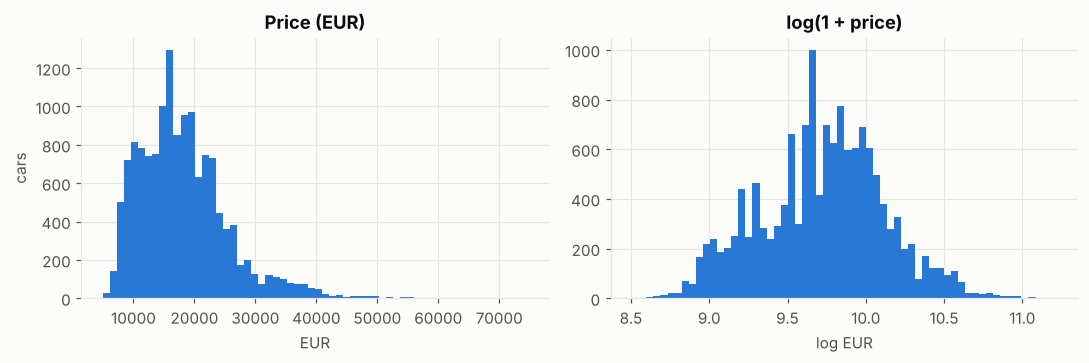

skew of price:        1.27
skew of log1p(price): -0.04


count    14242.0
mean     18101.0
std       7421.0
min       4950.0
25%      12950.0
50%      16950.0
75%      21900.0
95%      32498.0
max      74600.0
Name: price, dtype: float64

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(df[TARGET], bins=60, color=BLUE)
axes[0].set(title="Price (EUR)", xlabel="EUR", ylabel="cars")
axes[1].hist(np.log1p(df[TARGET]), bins=60, color=BLUE)
axes[1].set(title="log(1 + price)", xlabel="log EUR")
plt.tight_layout(); plt.show()

print(f"skew of price:        {df[TARGET].skew():.2f}")
print(f"skew of log1p(price): {np.log1p(df[TARGET]).skew():.2f}")
df[TARGET].describe(percentiles=[.25, .5, .75, .95]).round(0)

**Confirmed:** price has a long right tail (skew ≈ 1.3), and `log1p` brings it to ≈ 0.

Why this matters for a linear model: car prices move in **percentages** (an extra year costs roughly the same *share* of value on a cheap or an expensive car).
On the log scale those percentage effects become additive, which is what a linear model can represent. It also stops the few €60k+ cars from dominating the fit.
The model is trained on `log1p(price)` and predictions are converted back with `expm1` inside the pipeline.

## 4. The km column: real readings vs filled-in values

In [5]:
frac = df["km"] % 1 != 0
print("rows with fractional km:", int(frac.sum()), "of", len(df))
df.loc[frac, "km"].value_counts().head()

rows with fractional km: 875 of 14242


km
1647.362609     841
18035.130067     33
41748.576923      1
Name: count, dtype: int64

In [6]:
df.loc[frac].groupby("km").agg(rows=("price", "size"), mean_age=("age", "mean"))

,rows,mean_age
km,,
1647.362609,841,0.0
18035.130067,33,1.0
41748.576923,1,2.0


In [7]:
pd.crosstab(df["Type"], frac.rename("fractional km"))

fractional km,False,True
Type,,
Demonstration,737,30
Employee's car,897,8
New,646,723
Pre-registered,926,103
Used,10161,11


**Confirmed and sharpened.** In the raw file 1,024 km values are fractional (875 after removing duplicates). They are just **three repeated values**, one per age:
1,647.36 km for age 0, 18,035.13 for age 1 and 41,748.58 for age 2. Odometers don't read 1,647.36, so these are **group averages someone filled in**, mostly for `New` cars.

**Decision:** treat fractional km as unknown and refill it with the **median km of the same `Type`** (New, Used, …), learned on training rows (`KmImputer`).
A global median would give a brand-new car ~20,000 km. We also keep a 0/1 column `km_was_imputed` so the model can learn if those rows behave differently.

In [8]:
# median km per Type, using REAL readings only (fractional values excluded)
df[~frac].groupby("Type")["km"].median().round(0)

Type
Demonstration      3100.0
Employee's car    19840.0
New                  10.0
Pre-registered       10.0
Used              29502.0
Name: km, dtype: float64

A real New car typically shows a few km, not 1,647. A Used car shows about 30,000. That gap is why the fill value depends on Type.

## 5. Age covers only 0–3 years

In [9]:
pd.crosstab(df["age"], df["Type"])

Type,Demonstration,Employee's car,New,Pre-registered,Used
age,,,,,
0.0,612,115,1366,884,718
1.0,126,691,3,136,3327
2.0,27,84,0,8,2803
3.0,2,15,0,1,3324


Every car is **0 to 3 years old**. This is a big limitation: the model has never seen a 6-year-old car, so the app must not pretend it can price one.
It also limits the depreciation chart planned for Version 2 to this range.

## 6. Categories and rare levels

In [10]:
for col in ["make_model", "body_type", "Type", "Fuel", "Gearing_Type", "Drive_chain", "Paint_Type"]:
    print(col, df[col].value_counts().to_dict(), "\n")

make_model {'Audi A3': 2758, 'Opel Insignia': 2417, 'Audi A1': 2377, 'Opel Astra': 2305, 'Opel Corsa': 1994, 'Renault Clio': 1486, 'Renault Espace': 884, 'Renault Duster': 20, 'Audi A2': 1} 

body_type {'Sedans': 7230, 'Station wagon': 3405, 'Compact': 2710, 'Van': 735, 'Transporter': 87, 'Off-Road': 42, 'Coupe': 25, 'Convertible': 8} 

Type {'Used': 10172, 'New': 1369, 'Pre-registered': 1029, "Employee's car": 905, 'Demonstration': 767} 

Fuel {'Benzine': 7558, 'Diesel': 6619, 'LPG/CNG': 60, 'Electric': 5} 

Gearing_Type {'Manual': 7232, 'Automatic': 6546, 'Semi-automatic': 464} 

Drive_chain {'front': 14067, '4WD': 171, 'rear': 4} 

Paint_Type {'Metallic': 13682, 'Uni/basic': 549, 'Perl effect': 11} 



Some levels are tiny: `Audi A2` (1 row), `Renault Duster` (20), `Electric` fuel, `rear` drive.
A model cannot learn a reliable effect from 1–20 rows. **Decision:** the one-hot encoder pools any level with fewer than 20 *training* rows into an "infrequent" column (`min_frequency=20`), and the app only offers models with enough data.

No dummy is dropped "to reduce VIF". Dropping one level only moves the baseline. It does not change predictions, and Ridge/Lasso already handle the redundancy.

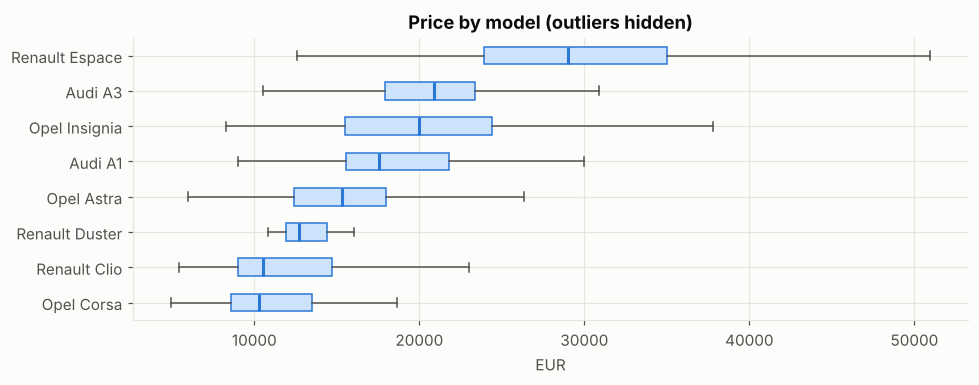

In [11]:
order = df.groupby("make_model")[TARGET].median().sort_values().index
order = [m for m in order if (df["make_model"] == m).sum() >= 20]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.boxplot([df.loc[df.make_model == m, TARGET] for m in order], tick_labels=order,
           orientation="horizontal", showfliers=False, patch_artist=True,
           boxprops=dict(facecolor="#cde2fb", color=BLUE), medianprops=dict(color=BLUE, linewidth=2),
           whiskerprops=dict(color=INK_2), capprops=dict(color=INK_2))
ax.set(title="Price by model (outliers hidden)", xlabel="EUR")
plt.tight_layout(); plt.show()

Model is the strongest single driver: a typical Espace lists for nearly three times a typical Corsa.

## 7. Numeric drivers

In [12]:
num = ["km", "age", "hp_kW", "Weight_kg", "Displacement_cc", "cons_comb", "Gears", "Previous_Owners", "Inspection_new"]
real = df[~frac]  # use real km readings only
corr = real[num].corrwith(np.log1p(real[TARGET])).sort_values()
corr.round(2)

age               -0.47
km                -0.41
Previous_Owners   -0.14
Inspection_new     0.02
cons_comb          0.20
Displacement_cc    0.26
Weight_kg          0.46
Gears              0.59
hp_kW              0.68
dtype: float64

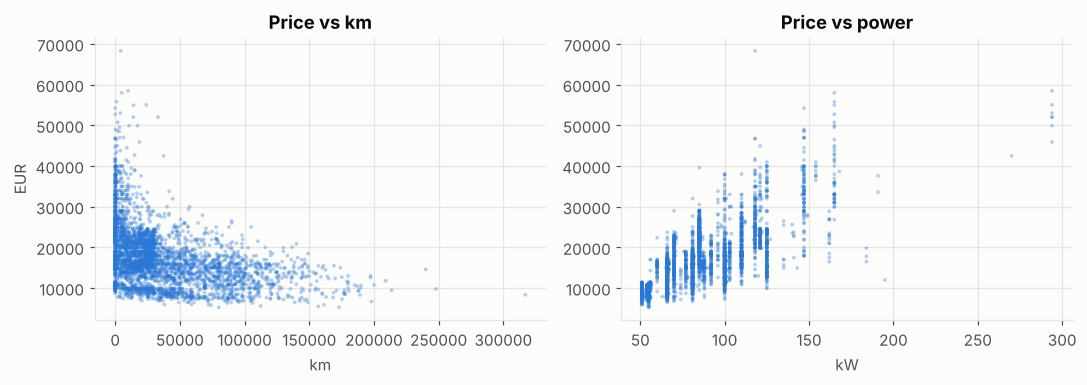

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
s = real.sample(4000, random_state=0)
axes[0].scatter(s["km"], s[TARGET], s=6, alpha=.35, color=BLUE, edgecolors="none")
axes[0].set(title="Price vs km", xlabel="km", ylabel="EUR")
axes[1].scatter(s["hp_kW"], s[TARGET], s=6, alpha=.35, color=BLUE, edgecolors="none")
axes[1].set(title="Price vs power", xlabel="kW")
plt.tight_layout(); plt.show()

Power (kW) and weight push price up; km and age pull it down. The spread of price widens as price rises, an early hint that errors will be larger for expensive cars.

## 8. Equipment lists → 0/1 flags

In [14]:
def items(col):
    return df[col].str.split(",").explode().str.strip()

for col in LIST_COLUMNS:
    share = items(col).value_counts() / len(df)
    print(f"{col}: {share.size} distinct items, {int((share < 0.01).sum())} on fewer than 1% of cars")
    print("   rarest:", share.tail(4).round(4).to_dict())

Comfort_Convenience: 38 distinct items, 5 on fewer than 1% of cars
   rarest: {'Leather seats': 0.0034, 'Wind deflector': 0.0029, 'Windshield': 0.0008, 'Electric Starter': 0.0001}
Entertainment_Media: 10 distinct items, 1 on fewer than 1% of cars
   rarest: {'CD player': 0.324, 'Digital radio': 0.1458, 'Sound system': 0.1384, 'Television': 0.0027}
Extras: 17 distinct items, 4 on fewer than 1% of cars
   rarest: {'Handicapped enabled': 0.0037, 'Tuned car': 0.0009, 'Sliding door': 0.0002, 'Right hand drive': 0.0002}
Safety_Security: 29 distinct items, 1 on fewer than 1% of cars
   rarest: {'Adaptive Cruise Control': 0.0871, 'Rear airbag': 0.06, 'Driver drowsiness detection': 0.0331, 'Night view assist': 0.0053}


**Confirmed:** four columns are comma-separated item lists. Each becomes one 0/1 column per item (`FeatureListBinarizer`).

**Decision:** keep an item only if at least **1% of training cars** have it. Items like *Electric Starter* (1 car) or *Right hand drive* (3 cars) would get an unreliable coefficient.
The 1% list here is shown for understanding only; the real list is learned inside the pipeline from the training split.

In [15]:
# Does equipment carry price information? Median price with vs without a few items.
rows = []
for col, item in [("Comfort_Convenience", "Navigation system"), ("Safety_Security", "Adaptive Cruise Control"),
                  ("Comfort_Convenience", "Air conditioning"), ("Extras", "Sport seats")]:
    has = df[col].str.split(",").apply(lambda xs, i=item: i in [x.strip() for x in xs])  # exact item match
    rows.append({"item": item, "share_of_cars": has.mean(), "median_with": df.loc[has, TARGET].median(),
                 "median_without": df.loc[~has, TARGET].median()})
pd.DataFrame(rows).round(2)

,item,share_of_cars,median_with,median_without
0,Navigation system,0.55,18890.0,14800.0
1,Adaptive Cruise Control,0.09,22000.0,16500.0
2,Air conditioning,0.95,16990.0,13994.5
3,Sport seats,0.20,18880.0,16365.0


Navigation and adaptive cruise control go with clearly higher prices. Part of that is *which* model has them (an Insignia vs a Corsa), so the model, not this table, should judge their own effect.

## Summary: what the data told us, and what we do about it

| Finding (verified here) | Decision | Where |
|---|---|---|
| 1,673 exact duplicates | drop before splitting | `src/cleaning.py` |
| price skew 1.27 → −0.04 with log1p (after dedup) | train on `log1p(price)` | `build_pipeline` |
| 875 km values are 3 repeated averages | refill with median km of same Type, learned on train; add a flag | `KmImputer` |
| only ages 0–3 | state it in the app; limit depreciation chart to 0–3 | app / v2 |
| rare categories (A2, Duster, Electric) | pool levels with < 20 training rows | `OneHotEncoder(min_frequency=20)` |
| 4 equipment-list columns | one 0/1 flag per item seen on ≥ 1% of training cars | `FeatureListBinarizer` |